# 09 · Independent validation against LVIS 2019 (regions never used for development)

**Question:** do the reclassified 30 m heights hold up **outside** the Alaska development sites (interior G-LiHT tiles 3457,
3553, Kenai 3836, 3928, Seward transects), across boreal and Arctic regions of Alaska and western Canada?

**Why LVIS 2019:** NASA's airborne LVIS laser flew ~1,700 ABoVE flight segments in summer 2019, the same summers ICESat-2
was collecting, so trees and shrubs have not grown or been cut between the two. The gridded 30 m product
(`ABoVE_LVIS_VegetationStructure_1923`, ORNL DAAC; local copies on ADAPT) gives, for each 30 m cell, the mean LVIS relative
heights RH10–RH100 and the number of LVIS shots.

**Why this is a real test:** nothing in configs v0.1–v0.6 was chosen using these regions. Settings that were chosen from the
development sites (e.g. the column-test settings) are judged here; any setting chosen *here* (the v0.3 `top_k`) is reported
region by region, so a choice that only works in one region is visible.

**Reference height of a segment:** mean LVIS RH98 along the segment's centre line (11 points, first to last photon), i.e.
the 30 m cells the footprint crosses, weighted by length. LVIS RH comes from a return waveform: over bare ground it reads
about 0.5–1 m, not 0, so in the shortest class a small positive ICESat-2 minus LVIS difference is expected even when right.

**Versions compared (all from the same ATL03 v007 photons):** **ATL08 · PhoREAL (today)** = ATL08 v007 photon classes cut into
30 m segments by SlideRule PhoREAL (our training data today); **ATL08 · our binning (control)** = the same classes in our
30 m segments (separates binning from classification); **reclassified v0.5** and **reclassified v0.6** = our photon classes
in our 30 m segments. v0.4 results are in the v0.5 run, v0.3 in the v0.4 run, v0.2 in the v0.3 run.

**Weight of this reference (17 Oct 2026, Paul Montesano):** LVIS is a full-waveform lidar whose noise floor is probably
0.5–1.0 m (to be verified), so its heights of short vegetation are not reliable. LVIS results are reported but weighed less
than discrete-return lidar (CanElevation, G-LiHT) and the Seward UAV; versions are not tuned or rejected mainly on LVIS.

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
CFGS = {"v0.5": ipl.load_config(REPO / "config" / "atl03_reclass_v0.5.yaml"), "v0.6": cfg}   # v0.4: runs/v0.5; v0.3: runs/v0.4; v0.2: runs/v0.3
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
LV = WORK / "lvis"; (LV / "photons").mkdir(parents=True, exist_ok=True)               # fetched photons per LVIS segment (shared)
OUT = RUN / "validation_lvis"; OUT.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| configs", {k: c["config_sha1"] for k, c in CFGS.items()}, "| run_dir:", RUN)

profile: adapt | configs {'v0.5': 'f419941dbc72', 'v0.6': '40e8f82a4112'} | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


## 1 · Which LVIS flight segments, in which regions

**Input:** the ORNL index of LVIS 2019 flight segments (one polygon per segment) and the boreal tile grid.

**What happens:** keep ABoVE 2019 segments (the GEDI 2019 campaign flew south of 37° N) that overlap boreal tiles and do
**not** touch the four development tiles; give each a region by its longitude and latitude; pick `N_PER_REGION` segments
per region at random (fixed seed) among those of at least `MIN_AREA_KM2`, so sites are spread out rather than hand-picked.

**Output:** `validation_lvis/selected_segments.parquet` and a map.

In [2]:
N_PER_REGION = 8          # LVIS flight segments per region
MIN_AREA_KM2 = 10         # skip small fragments
DEV_TILES = {3457, 3553, 3836, 3928}
ICESAT2_YEARS = [2019]    # same summer as the LVIS flights

def region_of(lon, lat):
    if lon < -141:
        return "Alaska Arctic" if lat >= 66.0 else "Alaska boreal"
    if lon < -124:
        return "Yukon / N BC"
    if lon < -110:
        return "NWT"
    return "Prairies / Shield"

idx = gpd.read_file(LV / "LVIS_ABoVE_spatial_footprints_2017_2019.gpkg", layer="LVISF3_2019")
idx["stem"] = idx.FILE.str.replace("_lvis_pt_cnt_30m.tif", "", regex=False)
idx = idx[idx.stem.str.contains("ABoVE2019")].copy()
idx["area_km2"] = idx.to_crs(3338).area / 1e6
c = idx.to_crs(4326).geometry.representative_point()
idx["lon"], idx["lat"] = c.x.values, c.y.values
idx["region"] = [region_of(a, b) for a, b in zip(idx.lon, idx.lat)]
tiles = gpd.read_file(cfg["paths"]["boreal_tiles"])
j = gpd.sjoin(idx[["stem", "geometry"]].to_crs(tiles.crs), tiles[["tile_num", "geometry"]], predicate="intersects")
in_boreal = set(j.stem)
touches_dev = set(j[j.tile_num.isin(DEV_TILES)].stem)
cand = idx[idx.stem.isin(in_boreal - touches_dev) & (idx.area_km2 >= MIN_AREA_KM2)]
sel = pd.concat([g.sample(min(N_PER_REGION, len(g)), random_state=0) for _, g in cand.groupby("region")])
sel = sel.assign(has_rasters=[os.path.exists(ref.lvis_paths(s, 2019)["RH098_mean"]) for s in sel.stem])
sel.to_parquet(OUT / "selected_segments.parquet")
print(f"{len(idx)} ABoVE 2019 segments; {len(in_boreal)} overlap boreal tiles; {len(touches_dev)} touch development tiles")
sel.groupby("region").agg(segments=("stem", "size"), area_km2=("area_km2", "sum"), rasters=("has_rasters", "sum")).round(0)

1740 ABoVE 2019 segments; 1579 overlap boreal tiles; 66 touch development tiles


,segments,area_km2,rasters
region,,,
Alaska Arctic,8,414.0,8
Alaska boreal,8,415.0,8
NWT,8,434.0,8
Prairies / Shield,8,429.0,8
Yukon / N BC,8,420.0,8


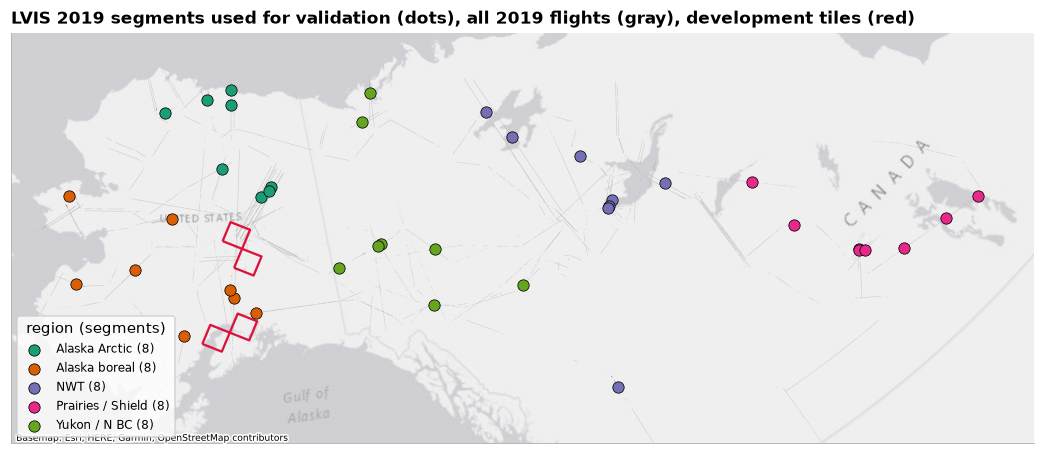

In [3]:
# Map: selected LVIS 2019 segments by region (Alaska Albers, ESRI Light Gray basemap); dots mark the selected segments
AK = 3338
REGION_COLORS = dict(zip(sorted(sel.region.unique()), ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e"]))
fig, ax = plt.subplots(figsize=(12, 6.5))
idx.to_crs(AK).plot(ax=ax, color="0.7", lw=0, alpha=0.6, zorder=2)
for reg, g in sel.groupby("region"):
    g2 = g.to_crs(AK)
    g2.plot(ax=ax, color=REGION_COLORS[reg], lw=0, zorder=3)
    c = g2.geometry.representative_point()
    ax.scatter(c.x, c.y, s=55, color=REGION_COLORS[reg], edgecolor="k", lw=0.5, zorder=5, label=f"{reg} ({len(g)})")
tiles[tiles.tile_num.isin(DEV_TILES)].to_crs(AK).boundary.plot(ax=ax, color="crimson", lw=1.5, zorder=4)
xmin, ymin, xmax, ymax = sel.to_crs(AK).total_bounds
pad = 0.06 * max(xmax - xmin, ymax - ymin)
ax.set_xlim(xmin - pad, xmax + pad); ax.set_ylim(ymin - pad, ymax + pad)
ps.add_basemap(ax, AK); ps.map_axes(ax, "LVIS 2019 segments used for validation (dots), all 2019 flights (gray), development tiles (red)")
ax.legend(loc="lower left", frameon=True, title="region (segments)")
fig.savefig(FIG / "09_lvis_selection_map.png")

## 2 · Fetch every ICESat-2 photon over each selected LVIS segment

**Input:** the selected segments.

**What happens:** for each LVIS segment, the ATL03 v007 granules of June–September 2019 crossing it are looked up in CMR,
and SlideRule returns every photon inside the segment's polygon (signal and solar background, with ATL08 v007 classes),
plus the ATL08 · PhoREAL (today) 30 m segments (as in our training files). Photons are saved per LVIS segment in the shared
work folder, so later config versions reuse them.

**Output:** `lvis/photons/<segment>.parquet`, `lvis/photons/<segment>_phoreal.parquet`, and a fetch log.

In [4]:
sliderule = ipl.sliderule_init()
log = []
for r in sel.itertuples():
    fn, fpr = LV / "photons" / f"{r.stem}.parquet", LV / "photons" / f"{r.stem}_phoreal.parquet"
    if fn.exists():
        log.append({"stem": r.stem, "status": "cached"}); continue
    aoi = gpd.GeoSeries([r.geometry], crs=idx.crs).to_crs(4326).iloc[0].buffer(0)
    aoi = aoi.simplify(0.0005)
    try:
        grs = ipl.granules_from_cmr(aoi, ICESAT2_YEARS, cfg["icesat2"]["months"], release=cfg["icesat2"]["release"])
        if not grs:
            log.append({"stem": r.stem, "status": "no granules"}); continue
        ph = ipl.fetch_photons(aoi, grs, cfg)
        if not len(ph):
            log.append({"stem": r.stem, "status": "no photons", "granules": len(grs)}); continue
        ph = ph.assign(lvis_stem=r.stem, region=r.region)
        ipl.write_parquet(ph, fn, ipl.provenance(cfg, lvis_stem=r.stem, granules=grs))
        pr = ipl.fetch_phoreal(aoi, grs, cfg)
        if len(pr):
            ipl.write_parquet(pr, fpr, ipl.provenance(cfg, lvis_stem=r.stem))
        log.append({"stem": r.stem, "status": "fetched", "granules": len(grs), "photons": len(ph), "tracks": ph.track_id.nunique()})
    except Exception as e:
        log.append({"stem": r.stem, "status": f"error: {type(e).__name__}: {str(e)[:120]}"})
log = pd.DataFrame(log); log.to_csv(OUT / "fetch_log.csv", index=False)
log.status.str.split(":").str[0].value_counts()

status
cached    40
Name: count, dtype: int64

## 3 · Classify, build 30 m segments for each version, attach the LVIS reference height

**What happens, per LVIS segment:**
1. The same photons are classified three ways: ATL08 v007 classes (as delivered), and our reclassifier with config v0.2 and
   with config v0.6 (v0.5 alongside for comparison).
2. 30 m segments are built from each (`segment_metrics`, same 30 m grid along track, so the versions line up segment by
   segment); the ATL08 · PhoREAL (today) segments are matched to the nearest segment on the same track.
3. Each segment gets the LVIS reference heights (RH95, RH98, RH100 and shots per cell) along its centre line.

**Output:** `validation_lvis/segments_lvis.parquet` (one row per segment, columns per version).

In [5]:
def build_segments(stem, region):
    """All versions' 30 m segments from the photons over one LVIS segment (val.segments_all_versions), plus LVIS RH."""
    ph = gpd.read_parquet(LV / "photons" / f"{stem}.parquet")
    fpr = LV / "photons" / f"{stem}_phoreal.parquet"
    base = val.segments_all_versions(ph, CFGS, cfg, gpd.read_parquet(fpr) if fpr.exists() else None)
    if not len(base):
        return None
    return ref.lvis_segment_metrics(base, stem, 2019).assign(region=region)

fn = OUT / "segments_lvis.parquet"
if fn.exists():
    segs = gpd.read_parquet(fn)
else:
    parts = []
    for r in sel.itertuples():
        if (LV / "photons" / f"{r.stem}.parquet").exists():
            try:
                b = build_segments(r.stem, r.region)
                if b is not None:
                    parts.append(b)
            except Exception as e:
                print(r.stem, "failed:", type(e).__name__, str(e)[:150])
    segs = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)
    ipl.write_parquet(segs, fn, ipl.provenance(cfg, configs={k: c["config_sha1"] for k, c in CFGS.items()}))
segs = segs[segs.lvis_n >= 6]            # at least half the centre-line points on valid LVIS cells
segs["light"] = np.where(segs.solar_elevation > 0, "day", "night")
segs["beam"] = np.where(segs.strong, "strong", "weak")
segs.groupby("region").agg(segments=("seg", "size"), lvis_segments=("lvis_stem", "nunique"),
                           lvis_rh98_median=("lvis_RH098_mean", "median"), day_share=("light", lambda s: (s == "day").mean())).round(2)

,segments,lvis_segments,lvis_rh98_median,day_share
region,,,,
Alaska Arctic,10202,8,0.63,0.85
Alaska boreal,4479,8,1.51,0.73
NWT,9809,8,4.30,0.63
Prairies / Shield,5412,8,5.23,0.61
Yukon / N BC,6672,8,4.38,0.62


## 4 · Results by reference height class and region

Mean bias and RMSE of each version against LVIS RH98, per LVIS height class, for each region and all regions together.
**Coverage** = share of segments for which a version reports a height. **Common segments** = segments every version reports,
so differences between versions are not due to different sets of segments.

coverage (share of segments with a height)


,ATL08 · PhoREAL (today),ATL08 · our binning (control),reclassified v0.5,reclassified v0.6
region,,,,
Alaska Arctic,0.87,0.54,0.46,0.46
Alaska boreal,0.75,0.66,0.41,0.41
NWT,0.94,0.85,0.53,0.53
Prairies / Shield,0.87,0.73,0.56,0.57
Yukon / N BC,0.86,0.73,0.52,0.52


bias  \
version                             ATL08 · PhoREAL (today)   
region            height_class                                
Alaska Arctic     0-1 m                                3.94   
                  1-2 m                                3.89   
                  10-15 m                             -1.93   
                  15-20 m                             -6.16   
                  2-5 m                                2.81   
                  20+ m                                 NaN   
                  5-10 m                               0.58   
                  all                                  2.68   
                  spurious_veg_rate                    0.44   
Alaska boreal     0-1 m                                2.94   
                  1-2 m                                3.23   
                  10-15 m                              8.05   
                  15-20 m                             10.53   
                  2-5 m                                3.86   
                  20+ m                                3.78   
                  5-10 m                               4.93   
                  all                                  3.56   
                  spurious_veg_rate                    0.53   
NWT               0-1 m                                1.50   
                  1-2 m                                2.09   
                  10-15 m                              0.30   
                  15-20 m                             -1.07   
                  2-5 m                                2.58   
                  20+ m                               -0.96   
                  5-10 m                               1.68   
                  all                                  1.49   
                  spurious_veg_rate                    0.40   
Prairies / Shield 0-1 m                                0.98   
                  1-2 m                                1.96   
                  10-15 m                             -0.19   
                  15-20 m                             -3.37   
                  2-5 m                                1.85   
                  20+ m                               -4.09   
                  5-10 m                               1.83   
                  all                                  0.96   
                  spurious_veg_rate                    0.33   
Yukon / N BC      0-1 m                                0.69   
                  1-2 m                                2.46   
                  10-15 m                              1.62   
                  15-20 m                             -0.95   
                  2-5 m                                2.70   
                  20+ m                               -2.75   
                  5-10 m                               2.98   
                  all                                  2.09   
                  spurious_veg_rate                    0.19   
all regions       0-1 m                                2.74   
                  1-2 m                                2.78   
                  10-15 m                              0.45   
                  15-20 m                             -1.70   
                  2-5 m                                2.63   
                  20+ m                               -1.68   
                  5-10 m                               1.95   
                  all                                  1.96   
                  spurious_veg_rate                    0.41   

                                                                   \
version                             ATL08 · our binning (control)   
region            height_class                                      
Alaska Arctic     0-1 m                                      4.95   
                  1-2 m                                      3.80   
                  10-15 m                                   -0.63   
                  15-20 m                        

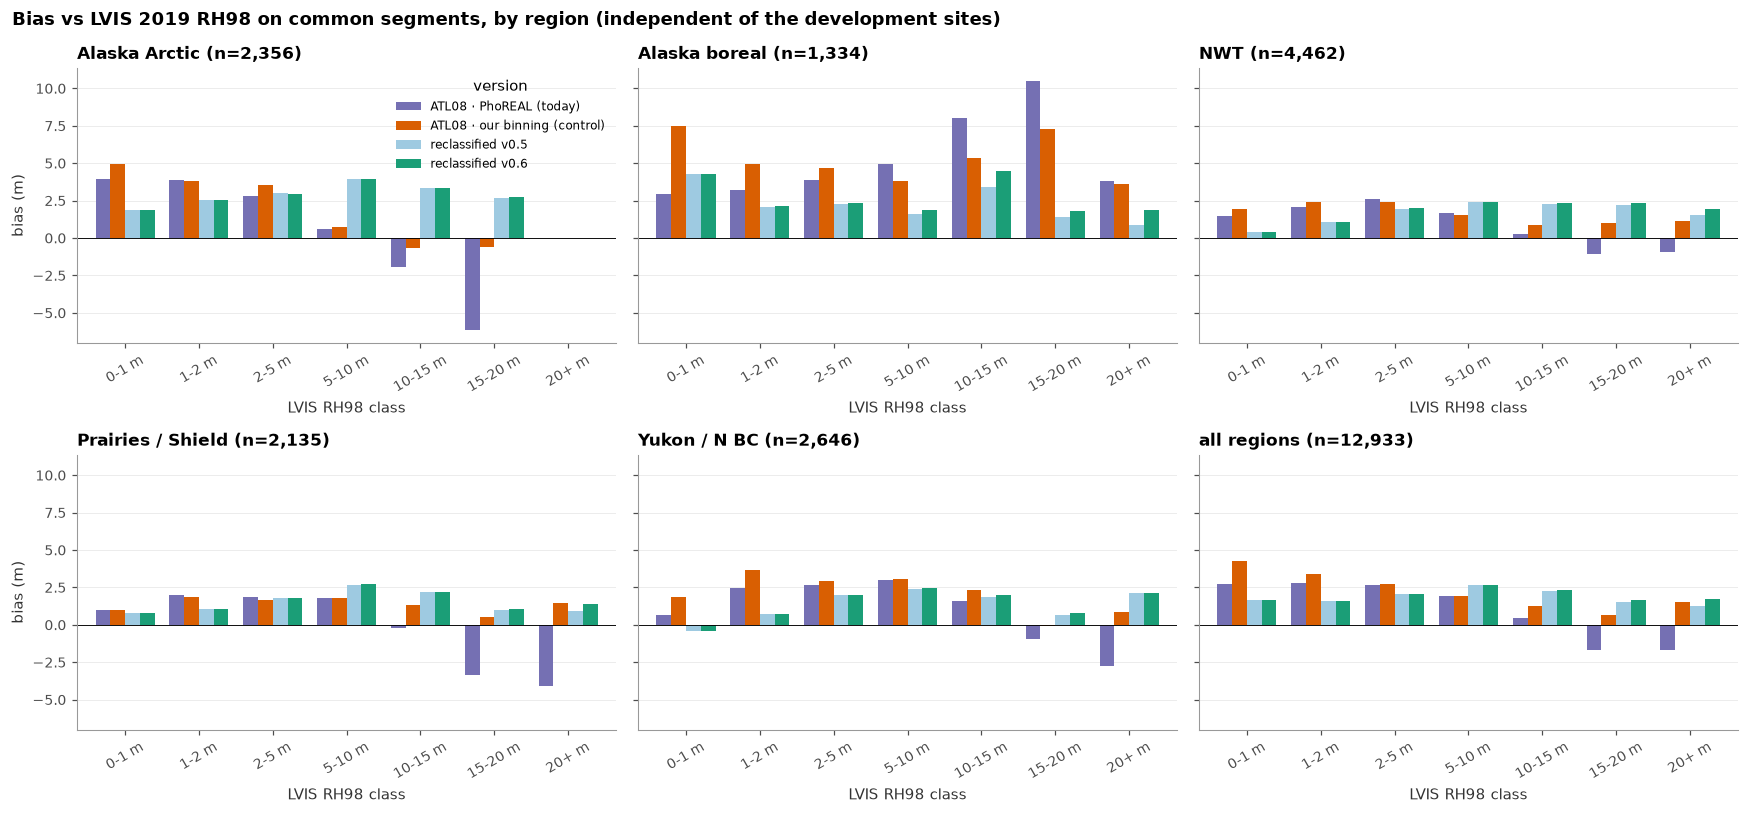

In [6]:
# Version names (17 Oct 2026): whose photon classes · who made the 30 m segments. All use ATL03 release 007 photons.
VERS = {val.LABEL_CURRENT: "h_canopy_phoreal", val.LABEL_CHECK: "h_canopy_atl08",
        "reclassified v0.5": "h_canopy_v05", "reclassified v0.6": "h_canopy_v06"}
VCOL = {val.LABEL_CURRENT: val.SCHEME_COLORS[val.LABEL_CURRENT], val.LABEL_CHECK: val.SCHEME_COLORS[val.LABEL_CHECK],
        "reclassified v0.5": "#9ecae1", "reclassified v0.6": val.SCHEME_COLORS[val.LABEL_NEW]}
NEWV = [k for k in VERS if k.startswith("reclassified")]       # candidate versions, oldest first; NEWV[-1] = this config
REF = "lvis_RH098_mean"
edges = cfg["validation"]["height_classes_m"]
cov = pd.DataFrame({k: segs.groupby("region")[c].apply(lambda s: s.notna().mean()) for k, c in VERS.items()}).round(2)
print("coverage (share of segments with a height)"); display(cov)
common = segs.dropna(subset=list(VERS.values()) + [REF])
rows = []
for reg, g in list(common.groupby("region")) + [("all regions", common)]:
    for k, c in VERS.items():
        rows.append(val.metrics_by_height_class(g[c], g[REF], edges, cfg["validation"]["spurious_veg"]).assign(region=reg, version=k))
res = pd.concat(rows).reset_index(names="height_class")
res.to_csv(OUT / "lvis_by_class_region_common.csv", index=False)
regions = sorted(common.region.unique()) + ["all regions"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharey=True)
for ax, reg in zip(axes.ravel(), regions):
    tt = res[(res.region == reg) & ~res.height_class.isin(["all", "spurious_veg_rate"])]
    pv = tt.pivot(index="height_class", columns="version", values="bias").reindex(val.height_class_labels(edges))[list(VERS)]
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[VCOL[c] for c in pv.columns], legend=(reg == regions[0]))
    ax.axhline(0, c="k", lw=0.6); ax.grid(axis="x", visible=False)
    ax.set_title(f"{reg} (n={int((common.region == reg).sum()) if reg != 'all regions' else len(common):,})"); ax.set_xlabel("LVIS RH98 class"); ax.set_ylabel("bias (m)")
for ax in axes.ravel()[len(regions):]:
    ax.axis("off")
fig.suptitle("Bias vs LVIS 2019 RH98 on common segments, by region (independent of the development sites)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "09_lvis_bias_by_region.png")
res.pivot_table(index=["region", "height_class"], columns="version", values=["n", "bias", "rmse"]).round(2)

### Tall-forest acceptance and spurious vegetation, per region
Acceptance criterion (LOG, 15 Oct): in every LVIS class ≥ 10 m and every region, a version's bias must be no more negative
than ATL08 · PhoREAL (today). Spurious vegetation: LVIS RH98 < 1 m but ICESat-2 > 2 m (share of those segments).

In [7]:
tall = [c for c in val.height_class_labels(edges) if int(c.split("-")[0].split("+")[0]) >= 10]
acc = []
for reg in sorted(common.region.unique()):
    for cl in tall:
        t = res[(res.region == reg) & (res.height_class == cl)].set_index("version")
        if t.empty or t.loc[val.LABEL_CURRENT, "n"] < 10:
            continue
        b7 = t.loc[val.LABEL_CURRENT, "bias"]
        acc.append({"region": reg, "class": cl, "n": int(t.loc[NEWV[-1], "n"]), "bias ATL08 · PhoREAL": b7,
                    **{f"{v} passes": bool(t.loc[v, "bias"] >= b7) for v in NEWV},
                    # restated criterion proposed 16 Oct (pending): |bias| no larger, and not more negative where today underestimates
                    **{f"{v} passes |bias|": bool(abs(t.loc[v, "bias"]) <= abs(b7) and (b7 >= 0 or t.loc[v, "bias"] >= b7)) for v in NEWV},
                    **{f"bias {v}": t.loc[v, "bias"] for v in NEWV}})
acc = pd.DataFrame(acc); acc.to_csv(OUT / "lvis_tall_acceptance.csv", index=False)
spur = res[res.height_class == "spurious_veg_rate"].pivot(index="region", columns="version", values="bias")[list(VERS)].round(3)
display(spur.rename_axis(None, axis=1))
acc.round(2)

,ATL08 · PhoREAL (today),ATL08 · our binning (control),reclassified v0.5,reclassified v0.6
region,,,,
Alaska Arctic,0.435,0.556,0.104,0.104
Alaska boreal,0.532,0.597,0.260,0.262
NWT,0.396,0.419,0.102,0.102
Prairies / Shield,0.333,0.294,0.119,0.119
Yukon / N BC,0.185,0.247,0.040,0.040
all regions,0.405,0.483,0.123,0.124


,region,class,n,bias ATL08 · PhoREAL,reclassified v0.5 passes,reclassified v0.6 passes,reclassified v0.5 passes |bias|,reclassified v0.6 passes |bias|,bias reclassified v0.5,bias reclassified v0.6
0,Alaska Arctic,10-15 m,185,-1.93,True,True,False,False,3.34,3.37
1,Alaska Arctic,15-20 m,24,-6.16,True,True,True,True,2.70,2.72
2,Alaska boreal,10-15 m,23,8.05,False,False,True,True,3.40,4.48
3,Alaska boreal,20+ m,11,3.78,False,False,True,True,0.86,1.90
4,NWT,10-15 m,804,0.30,True,True,False,False,2.30,2.32
5,NWT,15-20 m,283,-1.07,True,True,False,False,2.23,2.37
6,NWT,20+ m,46,-0.96,True,True,False,False,1.53,1.94
7,Prairies / Shield,10-15 m,353,-0.19,True,True,False,False,2.22,2.22
8,Prairies / Shield,15-20 m,165,-3.37,True,True,True,True,1.02,1.05
9,Prairies / Shield,20+ m,36,-4.09,True,True,True,True,0.93,1.37


## 5 · By signal: day/night × beam strength, and which LVIS percentile each version tracks

In [8]:
common = common.assign(signal_stratum=common.light + " · " + common.beam)
rows = []
for st, g in common.groupby("signal_stratum"):
    for k, c in VERS.items():
        e = g[c] - g[REF]
        rows.append({"stratum": st, "version": k, "n": len(g), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r2": val.r_squared(g[c], g[REF])})
sig = pd.DataFrame(rows); sig.to_csv(OUT / "lvis_by_signal.csv", index=False)
rows = []
for k, c in VERS.items():
    for p in ("RH095_mean", "RH098_mean", "RH100_mean"):
        d = common[[c, f"lvis_{p}"]].dropna(); e = d[c] - d[f"lvis_{p}"]
        rows.append({"version": k, "LVIS": p[:5], "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r2": val.r_squared(d.iloc[:, 0], d.iloc[:, 1])})
display(pd.DataFrame(rows).pivot(index="LVIS", columns="version", values=["bias", "rmse", "r2"]).round(2))
sig.pivot(index="stratum", columns="version", values=["n", "r2", "bias", "rmse"]).round(2)

bias                                \
version ATL08 · PhoREAL (today) ATL08 · our binning (control)   
LVIS                                                            
RH095                      2.75                          3.38   
RH098                      1.96                          2.59   
RH100                      0.58                          1.22   

                                                               rmse  \
version reclassified v0.5 reclassified v0.6 ATL08 · PhoREAL (today)   
LVIS                                                                  
RH095                2.85              2.89                    6.16   
RH098                2.06              2.10                    5.90   
RH100                0.69              0.73                    5.68   

                                                                           \
version ATL08 · our binning (control) reclassified v0.5 reclassified v0.6   
LVIS                                                                        
RH095                            6.43              6.76              6.77   
RH098                            6.11              6.43              6.43   
RH100                            5.74              6.15              6.14   

                             r2                                \
version ATL08 · PhoREAL (today) ATL08 · our binning (control)   
LVIS                                                            
RH095                      0.32                          0.34   
RH098                      0.32                          0.34   
RH100                      0.31                          0.33   

                                             
version reclassified v0.5 reclassified v0.6  
LVIS                                         
RH095                0.40              0.41  
RH098                0.41              0.42  
RH100                0.41              0.41

n                                \
version        ATL08 · PhoREAL (today) ATL08 · our binning (control)   
stratum                                                                
day · strong                    7689.0                        7689.0   
day · weak                       873.0                         873.0   
night · strong                  3957.0                        3957.0   
night · weak                     414.0                         414.0   

                                                                        r2  \
version        reclassified v0.5 reclassified v0.6 ATL08 · PhoREAL (today)   
stratum                                                                      
day · strong              7689.0            7689.0                    0.38   
day · weak                 873.0             873.0                    0.09   
night · strong            3957.0            3957.0                    0.26   
night · weak               414.0             414.0                    0.64   

                                                                \
version        ATL08 · our binning (control) reclassified v0.5   
stratum                                                          
day · strong                            0.40              0.41   
day · weak                              0.08              0.35   
night · strong                          0.27              0.40   
night · weak                            0.65              0.66   

                                                    bias  \
version        reclassified v0.6 ATL08 · PhoREAL (today)   
stratum                                                    
day · strong                0.41                    1.13   
day · weak                  0.35                    0.05   
night · strong              0.41                    4.06   
night · weak                0.66                    1.13   

                                                                \
version        ATL08 · our binning (control) reclassified v0.5   
stratum                                                          
day · strong                            2.52              2.42   
day · weak                              2.09              0.21   
night · strong                          3.00              2.03   
night · weak                            0.89             -0.39   

                                                    rmse  \
version        reclassified v0.6 ATL08 · PhoREAL (today)   
stratum                                                    
day · strong                2.44                    4.14   
day · weak                  0.21                    4.45   
night · strong              2.11                    8.65   
night · weak               -0.39                    3.35   

                                                                \
version        ATL08 · our binning (control) reclassified v0.5   
stratum                                                          
day · strong                            5.24              6.75   
day · weak                              5.69              4.98   
night · strong                          7.77              6.33   
night · weak                            3.17              3.19   

                                  
version        reclassified v0.6  
stratum                           
day · strong                6.75  
day · weak                  4.97  
night · strong              6.32  
night · weak                3.15

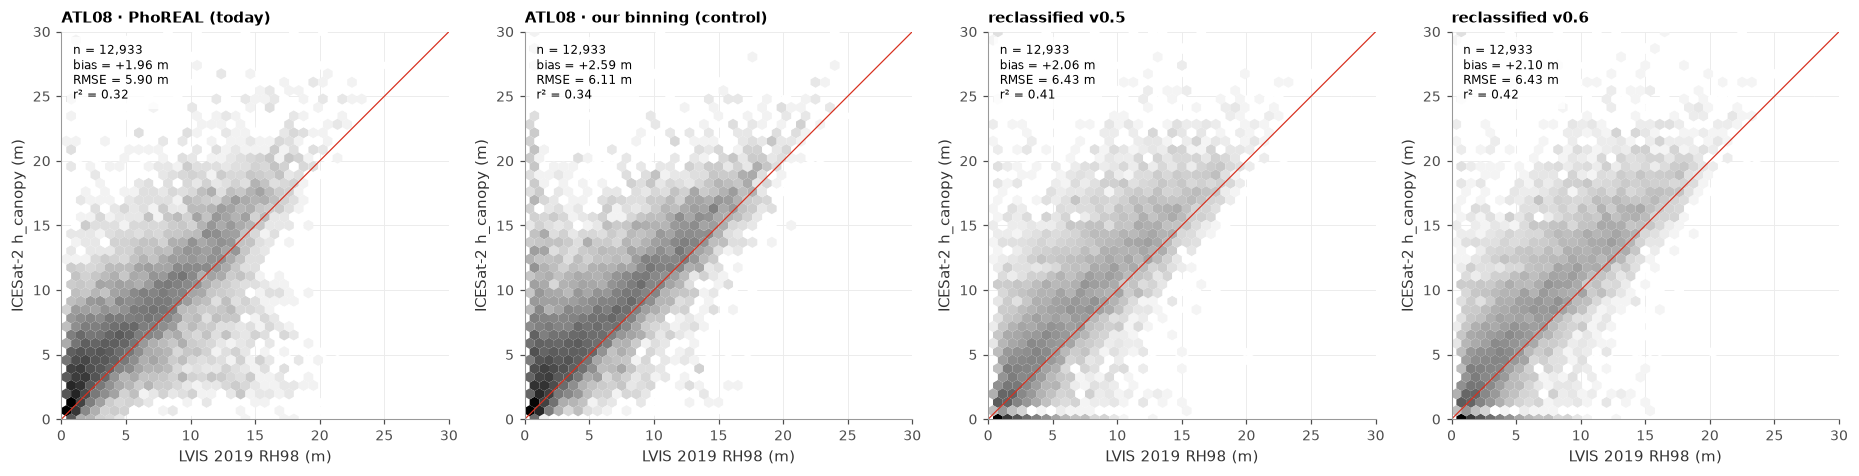

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
for ax, (k, c) in zip(axes, VERS.items()):
    val.plot_scatter(ax, common[c], common[REF], k, lim=30)
    ax.set_xlabel("LVIS 2019 RH98 (m)")
fig.tight_layout(); fig.savefig(FIG / "09_lvis_scatter.png")

### Zeros and non-zero accuracy by reference height class
**Why:** a 0 m height is right over bare ground (reference below ~1 m) and wrong over vegetation (above ~2 m). Mean bias
rewards writing 0 m, so it is read together with the share of zeros per class and the accuracy of the non-zero heights
(LOG, 16 Oct 2026). Common segments (every version reports a height).

zero_share                                \
version      ATL08 · PhoREAL (today) ATL08 · our binning (control)   
height_class                                                         
0-1 m                           0.04                           0.0   
1-2 m                           0.01                           0.0   
2-5 m                           0.01                           0.0   
5-10 m                          0.00                           0.0   
10-15 m                         0.00                           0.0   
15-20 m                         0.01                           0.0   
20+ m                           0.01                           0.0   

                                                            bias_nonzero  \
version      reclassified v0.5 reclassified v0.6 ATL08 · PhoREAL (today)   
height_class                                                               
0-1 m                     0.76              0.76                    2.87   
1-2 m                     0.36              0.36                    2.82   
2-5 m                     0.15              0.15                    2.68   
5-10 m                    0.03              0.03                    1.96   
10-15 m                   0.00              0.00                    0.48   
15-20 m                   0.00              0.00                   -1.58   
20+ m                     0.00              0.00                   -1.49   

                                                                                
version      ATL08 · our binning (control) reclassified v0.5 reclassified v0.6  
height_class                                                                    
0-1 m                                 4.26              9.42              9.41  
1-2 m                                 3.38              3.31              3.32  
2-5 m                                 2.76              2.95              2.96  
5-10 m                                1.90              2.93              2.97  
10-15 m                               1.26              2.32              2.39  
15-20 m                               0.65              1.61              1.73  
20+ m                                 1.53              1.27              1.74

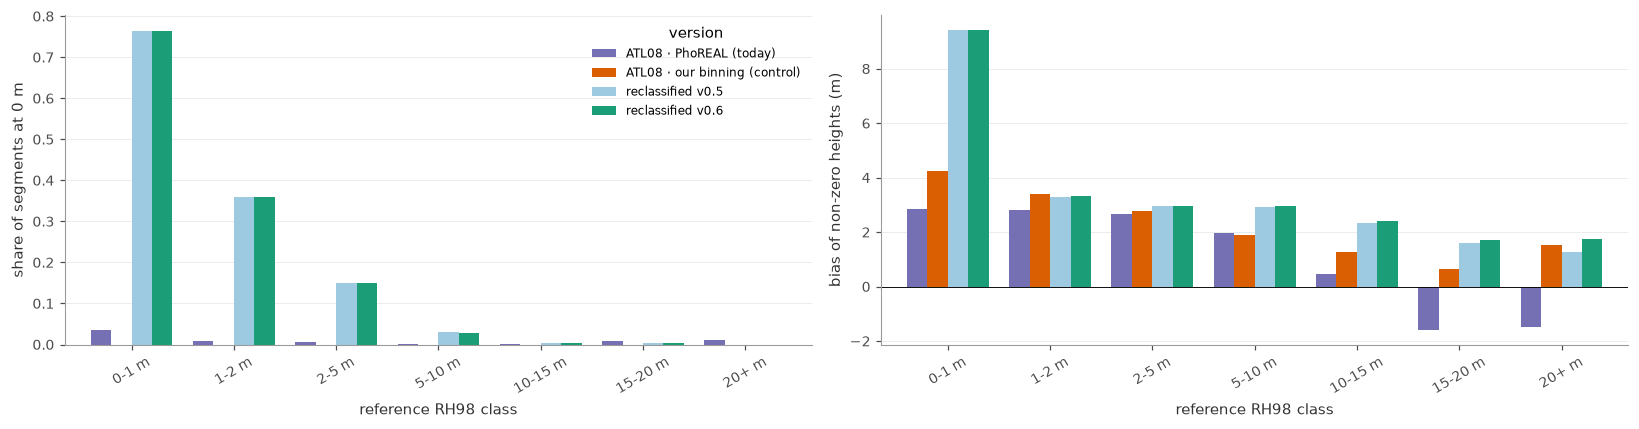

In [10]:
rows = []
for k, c in VERS.items():
    rows.append(val.zeros_by_height_class(common[c], common[REF], edges).assign(version=k))
zt = pd.concat(rows).reset_index(names="height_class")
zt.to_csv(OUT / "lvis_zeros_by_class.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, m, lab in [(axes[0], "zero_share", "share of segments at 0 m"), (axes[1], "bias_nonzero", "bias of non-zero heights (m)")]:
    pv = zt.pivot(index="height_class", columns="version", values=m).reindex(val.height_class_labels(edges))[list(VERS)]
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[VCOL[c] for c in pv.columns], legend=(m == "zero_share"))
    ax.axhline(0, c="k", lw=0.6); ax.grid(axis="x", visible=False); ax.set_ylabel(lab); ax.set_xlabel("reference RH98 class")
fig.tight_layout(); fig.savefig(FIG / "09_zeros_by_class.png")
zt.pivot(index="height_class", columns="version", values=["zero_share", "bias_nonzero"]).reindex(val.height_class_labels(edges)).round(2)

### By terrain slope
**Why:** v0.4 widens the ground window with the along-track ground slope (an 11 m footprint on a slope returns ground
over metres of height). Bias per slope class shows whether that removed the false vegetation on slopes without hurting
flat ground. Slope = along-track ground slope from the v0.6 ground surface (circumpolar-consistent; across-track slope
not known from one beam).

In [11]:
common = common.assign(slope_class=pd.cut(common["ground_slope_deg_v06"], [0, 5, 10, 20, 90], right=False,
                                          labels=["0-5°", "5-10°", "10-20°", "> 20°"]))
common["veg_class"] = np.where(common[REF] < 1, "reference < 1 m", np.where(common[REF] < 5, "1-5 m", "≥ 5 m"))
rows = []
for (sc, vc), g in common.groupby(["slope_class", "veg_class"], observed=True):
    for k, c in VERS.items():
        e = g[c] - g[REF]
        rows.append({"slope": sc, "reference": vc, "version": k, "n": len(g), "bias": e.mean(),
                     "spurious": ((g[REF] < 1) & (g[c] > 2)).sum() / max(1, (g[REF] < 1).sum())})
st = pd.DataFrame(rows); st.to_csv(OUT / "lvis_by_slope.csv", index=False)
st.pivot_table(index=["reference", "slope"], columns="version", values=["n", "bias"], observed=True).round(2)

bias                                \
version                ATL08 · PhoREAL (today) ATL08 · our binning (control)   
reference       slope                                                          
1-5 m           0-5°                      2.25                          2.80   
                10-20°                    4.38                          3.68   
                5-10°                     4.44                          3.64   
                > 20°                     5.10                          4.58   
reference < 1 m 0-5°                      2.74                          4.42   
                10-20°                    3.41                          2.74   
                5-10°                     2.56                          2.79   
                > 20°                    10.83                          3.41   
≥ 5 m           0-5°                      0.36                          1.27   
                10-20°                    4.11                          2.84   
                5-10°                     2.99                          2.35   
                > 20°                     5.04                          3.54   

                                                            \
version                reclassified v0.5 reclassified v0.6   
reference       slope                                        
1-5 m           0-5°                2.03              2.03   
                10-20°              0.79              0.86   
                5-10°               2.26              2.28   
                > 20°              -0.81             -0.58   
reference < 1 m 0-5°                1.87              1.87   
                10-20°              0.32              0.65   
                5-10°              -0.15             -0.17   
                > 20°               4.94              4.94   
≥ 5 m           0-5°                2.46              2.48   
                10-20°              2.44              2.74   
                5-10°               1.97              2.08   
                > 20°               1.07              1.60   

                                             n                                \
version                ATL08 · PhoREAL (today) ATL08 · our binning (control)   
reference       slope                                                          
1-5 m           0-5°                    3995.0                        3995.0   
                10-20°                   321.0                         321.0   
                5-10°                    486.0                         486.0   
                > 20°                    149.0                         149.0   
reference < 1 m 0-5°                    2103.0                        2103.0   
                10-20°                    27.0                          27.0   
                5-10°                    198.0                         198.0   
                > 20°                      3.0                           3.0   
≥ 5 m           0-5°                    4590.0                        4590.0   
                10-20°                   411.0                         411.0   
                5-10°                    500.0                         500.0   
                > 20°                    150.0                         150.0   

                                                            
version                reclassified v0.5 reclassified v0.6  
reference       slope                                       
1-5 m           0-5°              3995.0            3995.0  
                10-20°             321.0             321.0  
                5-10°              486.0             486.0  
                > 20°              149.0             149.0  
reference < 1 m 0-5°              2103.0            2103.0  
                10-20°              27.0              27.0  
                5-10°              198.0             198.0  
                > 20°                3.0               3.0  
≥ 5 m           0-5°              4590

## Results (config v0.6, 18 October 2026)

LVIS counts for less than the discrete-return references (waveform noise floor probably 0.5–1 m).
- **Tall-forest acceptance** (reclassified no more negative than today, per region × class ≥ 10 m): v0.6 passes 10 of 12 cells;
  it fails only in Alaska boreal (10–15 m, 20 m+; 23 and 11 segments), where today is already 8 and 4 m *taller* than LVIS.
  Against LVIS our forest heights read 1–4.5 m taller in every region (all regions, 10 m+: today −0.2 m, v0.6 +2.1 m), so the
  sign of the tall-forest error depends on whether a waveform or a canopy-height-model lidar is the reference.
- **Zeros:** 76 % of 0–1 m segments at 0 m (correct for bare ground), 3 % of 5–10 m, 0.3 % of 10 m+ (v0.5 the same).
- **Short vegetation:** spurious vegetation today 16 % → v0.6 6 %; but where v0.6 reports a height over LVIS 0–1 m (24 % of
  those segments) it is +9.4 m too tall on average, near LVIS's noise floor and the target of a plausibility cap.
- **v0.5 → v0.6:** within 0.1 m in every class except 20 m+ (+1.3 → +1.7 m); r² 0.467 → 0.472.